# News Text Classification

Classifying English news articles into four categories:
World, Sports, Business, and Sci/Tech.

This project explores classical machine learning models
and a small-scale DistilBERT fine-tuning experiment.

**Baseline: Bag of Words + Naive Bayes**


In [1]:
!pip install datasets

In [2]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")
train_data = dataset["train"]
test_data = dataset["test"]

print(train_data[0])


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [3]:
import pandas as pd

train_df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)

train_df.head()


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [4]:
import re
import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words]
    return " ".join(tokens)

train_df['clean_text'] = train_df['text'].apply(clean_text)
test_df['clean_text'] = test_df['text'].apply(clean_text)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [5]:
from collections import Counter

all_words = " ".join(train_df['clean_text']).split()
word_freq = Counter(all_words).most_common(10)

print(word_freq)


[('new', 21223), ('said', 19995), ('us', 19742), ('reuters', 17243), ('ap', 16148), ('first', 9040), ('two', 8925), ('world', 7473), ('monday', 7448), ('wednesday', 7317)]


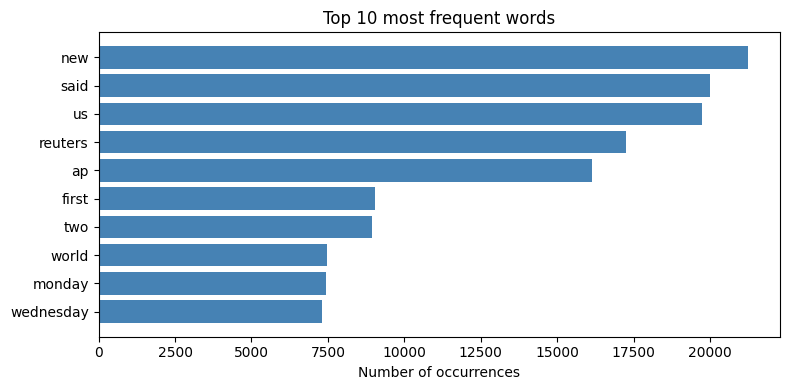

In [35]:
import matplotlib.pyplot as plt

words = [word for word, count in word_freq]
counts = [count for word, count in word_freq]

plt.figure(figsize=(8, 4))
plt.barh(words, counts, color="steelblue")
plt.xlabel("Number of occurrences")
plt.title("Top 10 most frequent words")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Most frequent words

This chart shows the 10 most frequent words in the training texts after cleaning and stopword removal. “New” and “said” occur most often. Words such as “Reuters” and “AP” also remain because they identify news sources.

In [36]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(train_df['clean_text'])
X_test = vectorizer.transform(test_df['clean_text'])

y_train = train_df['label']
y_test = test_df['label']


In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Baseline Accuracy:", accuracy)


Baseline Accuracy: 0.8885526315789474


In [8]:
from sklearn.metrics import f1_score

baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred, average='weighted')

print("Accuracy:", baseline_accuracy)
print("F1 Score:", baseline_f1)

Accuracy: 0.8885526315789474
F1 Score: 0.8881381363222945


**TF-IDF: Logistic Regression and SVM**

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2)
)

X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_test_tfidf = tfidf.transform(test_df['clean_text'])


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_tfidf, y_train)

y_pred_lr = lr.predict(X_test_tfidf)

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')

print("Logistic Regression Accuracy:", acc_lr)
print("Logistic Regression F1:", f1_lr)


Logistic Regression Accuracy: 0.9147368421052632
Logistic Regression F1: 0.9145564468575716


In [11]:
from sklearn.svm import LinearSVC

svm = LinearSVC()
svm.fit(X_train_tfidf, y_train)

y_pred_svm = svm.predict(X_test_tfidf)

acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print("SVM Accuracy:", acc_svm)
print("SVM F1:", f1_svm)


SVM Accuracy: 0.9131578947368421
SVM F1: 0.9129983514072133


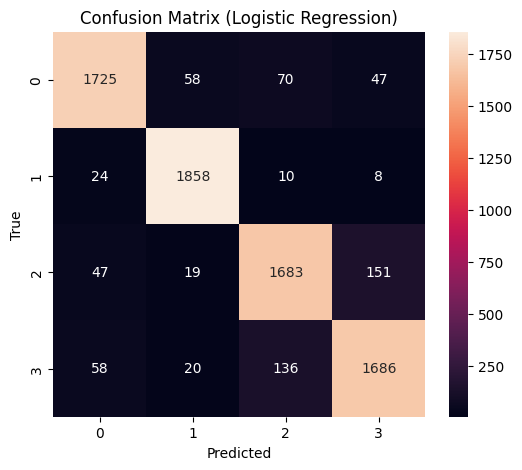

In [39]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix (Logistic Regression)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [13]:
comparison = pd.DataFrame({
    'Model': ['Naive Bayes (BoW)', 'Logistic Regression (TF-IDF)', 'SVM (TF-IDF)'],
    'Accuracy': [baseline_accuracy, acc_lr, acc_svm],
    'F1-Score': [baseline_f1, f1_lr, f1_svm]
})

comparison


,Model,Accuracy,F1-Score
0,Naive Bayes (BoW),0.888553,0.888138
1,Logistic Regression (TF-IDF),0.914737,0.914556
2,SVM (TF-IDF),0.913158,0.912998


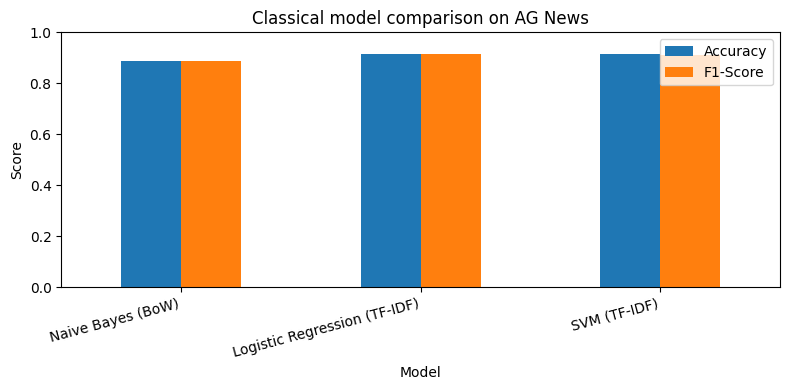

In [38]:
comparison.plot(
    x="Model",
    y=["Accuracy", "F1-Score"],
    kind="bar",
    figsize=(8, 4)
)

plt.title("Classical model comparison on AG News")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Classical model results

TF-IDF with Logistic Regression achieved 91.47% accuracy, compared with 91.32% for SVM and 88.86% for the BoW + Naive Bayes baseline. All three models were trained on 120,000 articles and evaluated on the same 7,600 test articles.

**Fine-tuning DistilBERT**

In [15]:
!pip install transformers datasets evaluate accelerate -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.5 MB/s eta 0:00:00


In [16]:
import torch
import pandas as pd
from datasets import load_dataset
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments
)
import evaluate


In [37]:
dataset = load_dataset("fancyzhx/ag_news")

label_names = ["World", "Sports", "Business", "Sci/Tech"]

In [18]:
tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding=True,
        truncation=True
    )

tokenized_ds = dataset.map(tokenize, batched=True)
tokenized_ds = tokenized_ds.remove_columns(["text"])
tokenized_ds = tokenized_ds.rename_column("label", "labels")
tokenized_ds.set_format("torch")


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [19]:
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [20]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [22]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)

    return {
        "accuracy": accuracy.compute(
            predictions=preds, references=labels
        )["accuracy"],
        "f1": f1.compute(
            predictions=preds,
            references=labels,
            average="weighted"
        )["f1"]
    }

In [23]:
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=100,
    save_total_limit=1
)

In [24]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"].shuffle(seed=42).select(range(1000)),
    eval_dataset=tokenized_ds["test"].shuffle(seed=42).select(range(500)),
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [25]:
trainer.train()

Step,Training Loss
100,0.862085


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=125, training_loss=0.8003282241821289, metrics={'train_runtime': 36.8064, 'train_samples_per_second': 27.169, 'train_steps_per_second': 3.396, 'total_flos': 85624598880576.0, 'train_loss': 0.8003282241821289, 'epoch': 1.0})

In [34]:
test_results = trainer.evaluate()

print("DistilBERT results")
print(f"Accuracy: {test_results['eval_accuracy']:.2%}")
print(f"F1-score: {test_results['eval_f1']:.4f}")

Training Loss,Validation Loss,Step,Accuracy,F1
0.862085,0.528251,125,0.856000,0.854792


DistilBERT results
Accuracy: 85.60%
F1-score: 0.8548


In [40]:
news = "The football team won the championship."

clean_news = clean_text(news)
news_vector = tfidf.transform([clean_news])
prediction = lr.predict(news_vector)[0]

categories = ["World", "Sports", "Business", "Sci/Tech"]

print("News:", news)
print("Predicted category:", categories[prediction])

News: The football team won the championship.
Predicted category: Sports
